# Data Understanding: EDA of the ParlaMint-UA sample

Interim report, component 2 (Data understanding), second data source: real Ukrainian parliamentary speech, sampled for annotation (plan Phase 2).

**Source:** [ParlaMint-UA 4.0](http://hdl.handle.net/11356/1859) (CC BY 4.0), Verkhovna Rada transcripts 2012–2023. `parlamint/prepare_parlamint.py` keeps regular (non-chair) Ukrainian speeches, splits them into sentences, filters to 2–60 words, drops duplicates and Russian quotes, and samples sentences so the length mix matches the Polish training data.

**Files** (`data/parlamint/`)
- `parlamint_ua_sample.csv`: the whole sample, 3,400 sentences, with a `split` column.
- `parlamint_ua_llm_train.csv`: 3,000 sentences to be labelled by the Lapa LLM (`parlamint/annotate_lapa.py`).
- `parlamint_ua_human_train.csv`: 250 sentences for human annotation (training).
- `parlamint_ua_gold_test.csv`: 150 sentences for human gold annotation (test, two annotators).

The two human files have one empty column per technique plus `done` and `comment`; annotators put 1 in the techniques that apply.

Runs on Colab (clones the repo) or locally (finds the repo root). CPU is enough.

In [1]:
import ast, subprocess, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

REPO_URL = "https://github.com/vivtrea/2026_NLP_Course_Project_Detecting_Persuasion_UKRParlTexts.git"
BRANCH = "main"

if "google.colab" in sys.modules:
    if not Path("repo").exists():
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, "repo"], check=True)  # private repo: use a URL with a token
    ROOT = Path("repo")
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())

DATA = ROOT / "data"
pd.set_option("display.max_colwidth", 200)
plt.rcParams["figure.dpi"] = 110
print("Data dir:", DATA.resolve())

Data dir: /content/repo/data


## 1. Load

In [2]:
PM = DATA / "parlamint"
SPLITS = ["llm_train", "human_train", "gold_test"]

sample = pd.read_csv(PM / "parlamint_ua_sample.csv")
sample["date"] = pd.to_datetime(sample["date"])
sample["year"] = sample["date"].dt.year
parts = {s: pd.read_csv(PM / f"parlamint_ua_{s}.csv") for s in SPLITS}

pl = pd.read_csv(DATA / "original" / "PL_train.csv")
pl["n_words"] = pl["content"].str.split().str.len()

sample.head(3)

,id,sitting,date,term,subcorpus,speaker_party,party_status,party_orientation,speaker_gender,context,content_uk,n_words,split,year
0,ParlaMint-UA_2013-09-05-m1.u38.s11,ParlaMint-UA_2013-09-05-m1,2013-09-05,7,Reference,"All-Ukrainian Union ""Fatherland"" (Batkivshchyna)",-,Centre,M,"В процесі підготовки законопроекту до другого читання було отримано від народних депутатів 29 пропозицій, з них 23 враховано, дві враховано частково, чотири відхилено. Загалом враховані пропозиції...","Введення до назви програми слова ""Україна"", включення положення щодо фінансування програми у повному обсязі.",14,llm_train,2013
1,ParlaMint-UA_2014-03-13-m0.u61.s7,ParlaMint-UA_2014-03-13-m0,2014-03-13,7,Reference,"All-Ukrainian Union ""Freedom"" (Svoboda) Faction",Coalition,Right to far-right,M,"Взагалі Всеукраїнське об'єднання ""Свобода"" вважає, що судова реформа, яка дуже потрібна українському суспільству, повинна починатися з того, що суддів місцевих судів треба обирати. Вони поміж собо...",А з'їзд суддів України мав би обирати голову і членів Верховного Суду.,12,llm_train,2014
2,ParlaMint-UA_2022-05-03-m0.u202.s5,ParlaMint-UA_2022-05-03-m0,2022-05-03,9,"COVID,War",European Solidarity Faction,Coalition,Centre-right,M,"Я прошу, щоб все ж таки почули це. Так от, законопроект пропонує наділити начальника військової адміністрації повним обсягом повноважень місцевих рад, і нова частина друга статті 10 визначає, що н...",От дуже важливий момент: без будь-якого зв'язку із заходами воєнного стану.,11,llm_train,2022


## 2. Size and split integrity

In [3]:
overview = sample.groupby("split").agg(
    sentences=("id", "size"),
    sittings=("sitting", "nunique"),
    first=("date", "min"),
    last=("date", "max"),
    median_words=("n_words", "median"),
).loc[SPLITS]
display(overview)

print("Missing values:", sample.isna().sum()[lambda s: s > 0].to_dict(), "(empty context = first sentence of a speech)")
print("Duplicate ids / texts:", sample["id"].duplicated().sum(), "/", sample["content_uk"].duplicated().sum())
for s, part in parts.items():
    same = set(part["id"]) == set(sample.loc[sample["split"] == s, "id"])
    print(f"{s}: {len(part)} rows, matches the sample split: {same}")

sittings = sample.groupby("split")["sitting"].apply(set)
for a, b in [("gold_test", "llm_train"), ("gold_test", "human_train"), ("human_train", "llm_train")]:
    print(f"Sittings shared by {a} and {b}: {len(sittings[a] & sittings[b])}")

,sentences,sittings,first,last,median_words
split,,,,,
llm_train,3000,893,2012-12-04,2023-09-06,14.0
human_train,250,102,2013-06-19,2023-02-07,13.0
gold_test,150,53,2013-03-19,2023-07-28,14.5


Missing values: {'context': 287} (empty context = first sentence of a speech)
Duplicate ids / texts: 0 / 0
llm_train: 3000 rows, matches the sample split: True
human_train: 250 rows, matches the sample split: True
gold_test: 150 rows, matches the sample split: True
Sittings shared by gold_test and llm_train: 0
Sittings shared by gold_test and human_train: 0
Sittings shared by human_train and llm_train: 0


Splits are made **per sitting**: no debate appears in two splits, so the gold test is not leaked into training (unlike the Polish data, where every document is in both train and test).

## 3. Time and corpus coverage

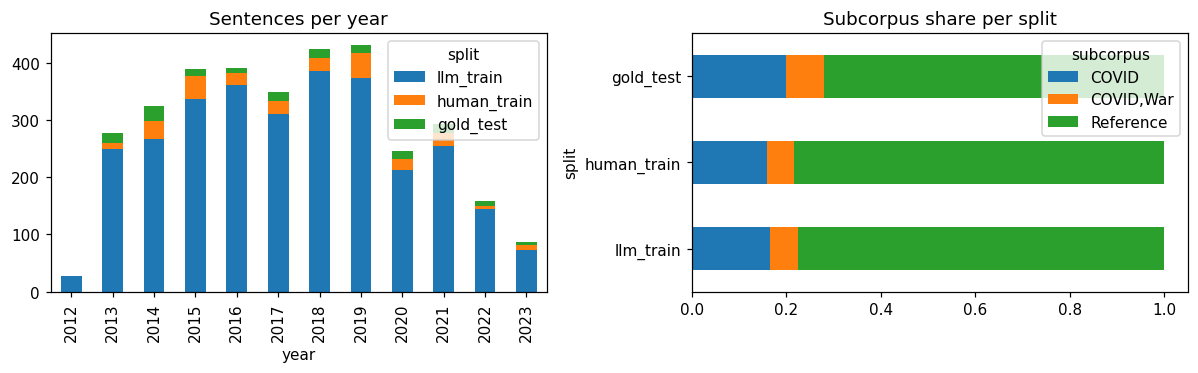

split,llm_train,human_train,gold_test,All
term,,,,
7,520,33,43,596
8,1631,147,64,1842
9,849,70,43,962
All,3000,250,150,3400


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
pd.crosstab(sample["year"], sample["split"])[SPLITS].plot.bar(stacked=True, ax=axes[0], title="Sentences per year")
pd.crosstab(sample["split"], sample["subcorpus"], normalize="index").loc[SPLITS].plot.barh(stacked=True, ax=axes[1], title="Subcorpus share per split")
plt.tight_layout(); plt.show()

display(pd.crosstab(sample["term"], sample["split"], margins=True)[SPLITS + ["All"]])

Terms 7–9 of the Rada. `Reference`, `COVID` and `COVID,War` are ParlaMint period labels (before COVID, COVID, full-scale war). Check how small the war share is.

## 4. Speakers

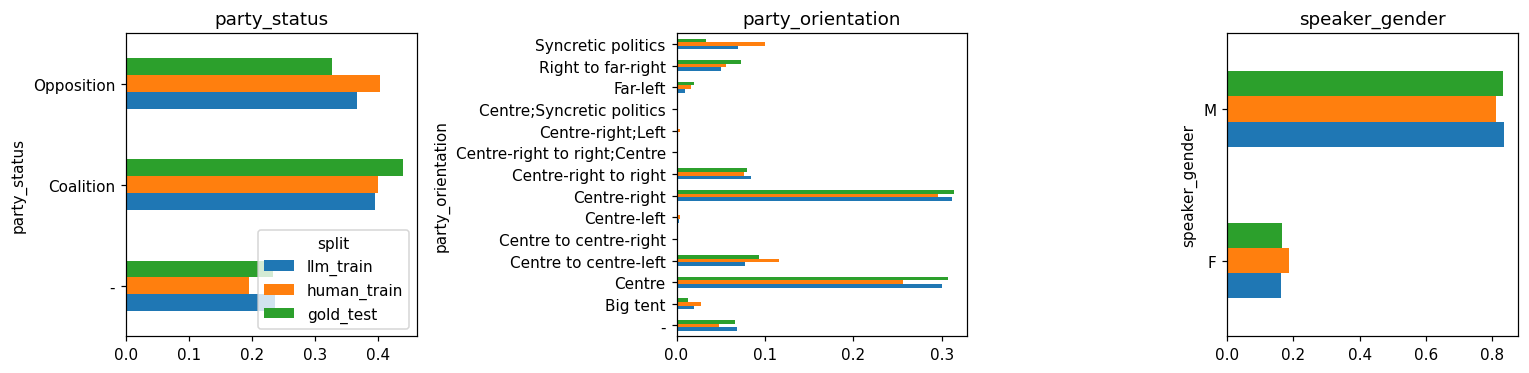

Parties: 56


,count
speaker_party,
"All-Ukrainian Union ""Fatherland"" Faction",490
Petro Poroshenko Bloc Faction,429
-,227
People's Front Faction,220
Radical Party of Oleh Liashko Faction,207
European Solidarity Faction,198
Self Reliance Faction,178
Servant of the People Faction,171
Opposition Bloc Faction,152


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["party_status", "party_orientation", "speaker_gender"]):
    pd.crosstab(sample[col], sample["split"], normalize="columns")[SPLITS].plot.barh(ax=ax, title=col, legend=ax is axes[0])
plt.tight_layout(); plt.show()

print("Parties:", sample["speaker_party"].nunique())
sample["speaker_party"].value_counts().head(10)

## 5. Sentence length vs the Polish training data

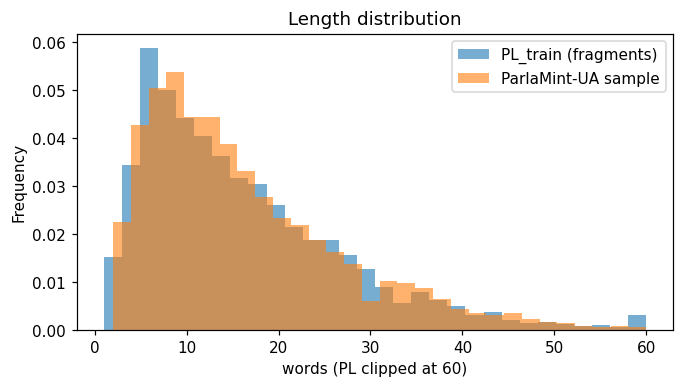

,PL_train,ParlaMint
n_words,,
"(1, 4]",0.091,0.080
"(4, 10]",0.305,0.300
"(10, 20]",0.328,0.336
"(20, 40]",0.242,0.247
"(40, 60]",0.035,0.037


In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
pl["n_words"].clip(upper=60).plot.hist(bins=30, alpha=0.6, density=True, label="PL_train (fragments)", ax=ax)
sample["n_words"].plot.hist(bins=30, alpha=0.6, density=True, label="ParlaMint-UA sample", ax=ax)
ax.set_xlabel("words (PL clipped at 60)"); ax.legend(); ax.set_title("Length distribution")
plt.show()

bins = [1, 4, 10, 20, 40, 60]  # the bins prepare_parlamint.py matched on
display(pd.DataFrame({
    "PL_train": pd.cut(pl["n_words"], bins).value_counts(normalize=True),
    "ParlaMint": pd.cut(sample["n_words"], bins).value_counts(normalize=True),
}).sort_index().round(3))

In [7]:
# token lengths for XLM-R, with and without the preceding context
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("xlm-roberta-base")
sent = [len(ids) for ids in tok(sample["content_uk"].tolist())["input_ids"]]
both = [len(ids) for ids in tok(sample["context"].fillna("").tolist(), sample["content_uk"].tolist())["input_ids"]]
lengths = pd.DataFrame({"sentence": sent, "context + sentence": both})
display(lengths.describe(percentiles=[.5, .9, .99]).round(1))
for max_len in (128, 256):
    print(f"max_length={max_len}: truncated", (lengths > max_len).mean().round(4).to_dict())

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

,sentence,context + sentence
count,3400.0,3400.0
mean,29.5,79.1
std,18.2,37.6
min,5.0,8.0
50%,25.0,76.0
90%,56.0,128.0
99%,88.0,183.0
max,112.0,260.0


max_length=128: truncated {'sentence': 0.0, 'context + sentence': 0.0997}
max_length=256: truncated {'sentence': 0.0, 'context + sentence': 0.0003}


## 6. Examples

In [8]:
for s in SPLITS:
    row = sample[sample["split"] == s].sample(1, random_state=3).iloc[0]
    print(f"[{s}] {row['date']:%Y-%m-%d}, {row['speaker_party']} ({row['party_status']})")
    print("  context: ", row["context"])
    print("  sentence:", row["content_uk"])
    print()

[llm_train] 2021-05-18, All-Ukrainian Union "Fatherland" Faction (Opposition)
  context:  Важливо, щоби всі ті, які повірили в благі наміри, вони побачили реальні кроки. Ну чому ми сьогодні знову говоримо про уряд і про їхні обіцянки?
  sentence: Уряд ми повинні за ці обіцянки гнати в шию, якщо вони вчасно не виконують.

[human_train] 2014-04-10, All-Ukrainian Union "Fatherland" Faction (Coalition)
  context:  Я вибачаюсь, я хочу сказати, що все-все так, а то трошечки не так.
  sentence: Моя пропозиція була трошки інша.

[gold_test] 2018-11-20, People's Front Faction (Coalition)
  context:  І децентралізація питань, які стосуються архітектурно-будівельного контролю, так само процес правильний. Але, на жаль, мусимо констатувати, що разом з децентралізацією прав і повноважень так само відбувається процес децентралізації корупції.
  sentence: І не реагувати на це ми не маємо права.



In [9]:
# sentences the sentence splitter may have cut badly: no final punctuation, or starting in lower case
odd = sample[~sample["content_uk"].str.rstrip().str[-1].isin(list(".!?…)»\"")) | sample["content_uk"].str[0].str.islower()]
print(f"{len(odd)} of {len(sample)} sentences look oddly split")
odd[["context", "content_uk"]].head(8)

19 of 3400 sentences look oddly split


,context,content_uk
336,NaN,політичну кар'єру будувати на неправді.
503,NaN,з виконанням певних робіт на території вони б компенсувалися надходженнями до місцевих бюджетів.
809,NaN,"і тоді ніяка ""клептократична Україна"" більше не перемагатиме."
815,NaN,які підривають основи нашої державності.
871,NaN,давайте працювати на єдність нашої країни.
911,NaN,чому експертиза зводиться виключно до державних експертів?
973,NaN,"окремих його положень нормам Конституції України, вимогам Регламенту Верховної Ради України та Бюджетного кодексу України, в зв’язку з відсутністю належного фінансово-економічного обґрунтування, а..."
1291,NaN,"залишають для чиновників 10 прожиткових мінімумів, а працюючих пенсіонерів забирають останні копійки."


## 7. Annotation progress

The human files are empty until annotators fill them in; rerun this section afterwards. LLM labels are written by `annotate_lapa.py` to `data/parlamint/llm/` (or `ANNOTATION_OUT_DIR`).

In [10]:
for s in ["human_train", "gold_test"]:
    part = parts[s]
    techniques = part.columns[part.columns.get_loc("content_uk") + 1 : part.columns.get_loc("done")]
    done = part[part["done"].notna()]
    print(f"{s}: {len(done)} of {len(part)} rows done")
    if len(done):
        labels = done[techniques].notna()
        print(f"  persuasive share: {labels.any(axis=1).mean():.2f}")
        display(labels.sum().sort_values(ascending=False).to_frame("count").T)

llm_files = sorted((PM / "llm").glob("*.csv")) if (PM / "llm").exists() else []
print("LLM label files:", [f.name for f in llm_files] or "none yet")

human_train: 0 of 250 rows done
gold_test: 0 of 150 rows done
LLM label files: none yet


## 8. Findings

Fill in from the outputs above for the slides. Points to check:
- **Size:** 3,400 sentences from how many sittings, 2012–2023; 3,000 for LLM labels, 400 for humans.
- **Split:** sitting-level, no shared debates; a stricter split than the Polish data.
- **Coverage:** terms, subcorpora (pre-COVID, COVID, war), coalition vs opposition, party orientation, gender balance.
- **Length:** matches PL_train by design; context + sentence still fits in 256 tokens.
- **Quality:** share of oddly split sentences from the regex splitter.
- **Labels:** none yet; the annotation status and, later, label distribution vs PL.